# Mercado Laboral y Salarios en Tecnología (Chile y Latinoamérica 2024–2026)
### Certificado Profesional de Análisis de Datos de Google • Caso Práctico
*Caso de estudio con cliente y partes interesadas simulados (ejercicio académico)*

**Autor:** Manuel Yáñez Orellana  
**Rol:** Analista de Datos  
**Patrocinadores Simulados:** Consultora de RRHH Tech & Academia de Formación Digital (Chile)  
**Versión del Estudio:** v1.12.1 (2026-11-21)  
**Trazabilidad:** Tablero en Tableau Public: pendiente de publicación (datos preparados en Datos_Consolidados_Tableau_Public.xlsx) | Cuaderno y dataset en Kaggle: pendientes de publicación

---

## Resumen Ejecutivo y Marco de Negocio
Este cuaderno ejecuta el análisis integral del talento tech en Chile y Latinoamérica a partir de **4 poblaciones independientes** (72.797 registros crudos validados):
1. **Get on Board (2026):** Demanda laboral activa en Chile y vacantes remotas aplicables (corte al 2026-11-10, 679 ofertas en alcance, 235 salarios válidos).
2. **Stack Overflow Developer Survey (2024):** Adopción de habilidades y salarios de 3.074 desarrolladores encuestados en 19 países de LatAm (133 en Chile; 1.341 salarios válidos).
3. **Data Science Salaries (2020–2024):** Serie histórica internacional de roles de datos (6.599 registros; 5.305 residentes en EE.UU.).
4. **INE ESI 2025 (Chile):** Línea base oficial nacional de ingresos laborales en Chile ($680.000 CLP / $701 USD mediana mensual).

**Regla de Oro Metodológica:** Ninguna población se fusiona a nivel de fila ni se promedian juntas fuentes con marcos de muestreo disímiles. Toda conclusión cuantitativa exige suficiencia muestral ($N \ge 30$, CLT).

In [1]:
from pathlib import Path
import glob
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

# Configuración visual adaptada al estándar de accesibilidad del Curso 6
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['font.size'] = 10
plt.rcParams['figure.autolayout'] = True

# Detección determinista de rutas según el entorno (Kaggle o local)
LOCAL_DATA = Path("03_Fase_Procesar_Process/datos_limpios_processed")
KAGGLE_CANDIDATES = glob.glob("/kaggle/input/**/GetOnBoard_Vacantes_*.csv", recursive=True)

if KAGGLE_CANDIDATES:
    DATA_DIR = Path(KAGGLE_CANDIDATES[0]).parent
    print(f"Ambiente Kaggle detectado. Directorio de datos: {DATA_DIR}")
elif LOCAL_DATA.exists():
    DATA_DIR = LOCAL_DATA
    print(f"Ambiente local detectado. Directorio de datos: {DATA_DIR}")
else:
    DATA_DIR = Path(".")
    print(f"Directorio de datos por defecto: {DATA_DIR}")

Ambiente local detectado. Directorio de datos: 03_Fase_Procesar_Process/datos_limpios_processed


In [2]:
# Ingesta de las 4 poblaciones validadas (Fase 2: Preparar • Cursos 3 y 4)
gob_vac = pd.read_csv(DATA_DIR / "GetOnBoard_Vacantes_2026_20261111_v01_clean.csv")
gob_hab = pd.read_csv(DATA_DIR / "GetOnBoard_Habilidades_2026_20261111_v01_clean.csv")
so_lat  = pd.read_csv(DATA_DIR / "StackOverflow_LatAm_2024_20261111_v01_clean.csv")
so_tec  = pd.read_csv(DATA_DIR / "StackOverflow_Tecnologias_2024_20261111_v01_clean.csv")
dss     = pd.read_csv(DATA_DIR / "DataScienceSalaries_2020_2024_20261111_v01_clean.csv")
ine     = pd.read_csv(DATA_DIR / "INE_ESI_2025_ReferenciaNacional_20261111_v01_clean.csv")

print(f"Get on Board Vacantes: {len(gob_vac):,} filas | Habilidades: {len(gob_hab):,} filas")
print(f"Stack Overflow LatAm:  {len(so_lat):,} filas | Tecnologías: {len(so_tec):,} filas")
print(f"Data Science Salaries: {len(dss):,} filas")
mediana_ine = int(ine[ine['indicador'] == 'Ingreso Mediano Nacional Ocupados']['monto_clp_mensual'].iloc[0])
mediana_ine_usd = round(mediana_ine / 969.8, 2)
print(f"INE ESI 2025 Nacional = {mediana_ine:,} CLP ({mediana_ine_usd:,} USD aprox.)")

Get on Board Vacantes: 679 filas | Habilidades: 1,749 filas
Stack Overflow LatAm:  3,074 filas | Tecnologías: 31,759 filas
Data Science Salaries: 6,599 filas
INE ESI 2025 Nacional = 680,000 CLP (701.18 USD aprox.)


## 1. Arquitectura Relacional en SQLite (Fase 4 • Curso 5)
Carga de las tablas en SQLite en memoria para consultar las tablas normalizadas (Ancho + Largo).
Se controlan las uniones 1:N mediante `LEFT JOIN` y `COUNT(DISTINCT ...)` para evitar la duplicación de salarios y sesgos en denominadores.

In [3]:
conn = sqlite3.connect(":memory:")
gob_vac.to_sql("vacantes", conn, index=False)
gob_hab.to_sql("vacante_habilidades", conn, index=False)
so_lat.to_sql("so_encuestados", conn, index=False)
so_tec.to_sql("so_tecnologias", conn, index=False)
dss.to_sql("dss", conn, index=False)
ine.to_sql("ine", conn, index=False)

q_integridad = """
SELECT 
    'Get on Board 2026' AS poblacion,
    COUNT(DISTINCT v.job_id) AS total_vacantes_unicas,
    COUNT(h.job_id) AS filas_expandidas_1_n,
    ROUND(AVG(v.salario_mensual_usd), 2) AS media_correcta_sin_duplicacion,
    ROUND(AVG(v_dup.salario_mensual_usd), 2) AS media_naive_con_duplicacion
FROM vacantes v
LEFT JOIN vacante_habilidades h ON v.job_id = h.job_id
LEFT JOIN (
    SELECT v2.job_id, v2.salario_mensual_usd 
    FROM vacantes v2 
    JOIN vacante_habilidades h2 ON v2.job_id = h2.job_id
) v_dup ON 1=1
WHERE v.salario_valido_flag = 1
GROUP BY 1;
"""
df_int = pd.read_sql(q_integridad, conn)
display(df_int)

,poblacion,total_vacantes_unicas,filas_expandidas_1_n,media_correcta_sin_duplicacion,media_naive_con_duplicacion
0,Get on Board 2026,235,1140348,2928.93,2943.44


## 2. Pregunta de Investigación 1 (P1): Demanda vs. Adopción Tecnológica
**Pregunta de Negocio (P1):** *¿Cuáles son las tecnologías más demandadas por los empleadores tech en Chile y qué brechas existen frente a las habilidades que declaran los profesionales?*

**Hallazgo Clave (PASO 4.1):** 3 tecnologías superan el 20% de las ofertas en Get on Board: SQL (32,8%, 223), AWS (30,0%, 204) y Python (28,4%, 193). En plataformas Cloud, solo AWS supera el umbral del 20%, mientras que Google Cloud (17,23%, 117) y Microsoft Azure (17,1%, 116) se sitúan por debajo del umbral estratégico.

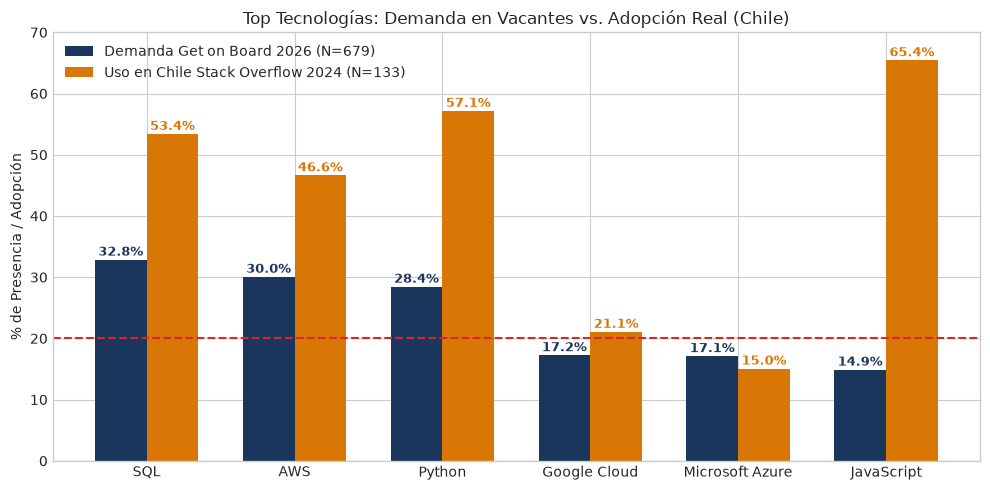

In [4]:
q_p1 = """
SELECT 
    h.tecnologia,
    COUNT(DISTINCT h.job_id) AS ofertas_gob,
    ROUND(COUNT(DISTINCT h.job_id) * 100.0 / 679, 2) AS pct_demanda_gob,
    COALESCE(t_so.pct_adopcion_chile, 0) AS pct_so_chile
FROM vacante_habilidades h
LEFT JOIN (
    SELECT 
        tecnologia,
        ROUND(COUNT(DISTINCT ResponseId) * 100.0 / 133, 2) AS pct_adopcion_chile
    FROM so_tecnologias
    WHERE pais = 'Chile'
    GROUP BY tecnologia
) t_so ON h.tecnologia = t_so.tecnologia
WHERE h.tecnologia IN ('SQL', 'AWS', 'Python', 'Microsoft Azure', 'Google Cloud', 'JavaScript')
GROUP BY h.tecnologia
ORDER BY pct_demanda_gob DESC;
"""
df_p1 = pd.read_sql(q_p1, conn)

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_p1))
width = 0.35

rects1 = ax.bar(x - width/2, df_p1['pct_demanda_gob'], width, label='Demanda Get on Board 2026 (N=679)', color='#1B365D')
rects2 = ax.bar(x + width/2, df_p1['pct_so_chile'], width, label='Uso en Chile Stack Overflow 2024 (N=133)', color='#D97706')

ax.set_ylabel('% de Presencia / Adopción')
ax.set_title('Top Tecnologías: Demanda en Vacantes vs. Adopción Real (Chile)')
ax.set_xticks(x)
ax.set_xticklabels(df_p1['tecnologia'])
ax.legend()
ax.axhline(20.0, color='#DC2626', linestyle='--', linewidth=1.5, label='Umbral Mínimo de Presencia (20%)')

for r in rects1:
    h = r.get_height()
    ax.annotate(f'{h:.1f}%', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', fontsize=9, color='#1B365D', fontweight='bold')
for r in rects2:
    h = r.get_height()
    ax.annotate(f'{h:.1f}%', xy=(r.get_x() + r.get_width()/2, h), xytext=(0, 3),
                textcoords="offset points", ha='center', fontsize=9, color='#D97706', fontweight='bold')

ax.set_ylim(0, 70)
plt.show()

## 3. Pregunta de Investigación 2 (P2): Progresión Salarial y Bandas de Seniority
**Pregunta de Negocio (P2):** *¿Cuál es la estructura salarial por nivel de experiencia y en qué tramo ocurre el mayor salto porcentual?*

**Hallazgo Clave (PASO 4.2):** En Chile Local (Get on Board 2026), la mediana salarial es $2.250 USD en Semi-Senior (65, p25 $2.000, p75 $2.500) y $2.750 USD en Senior (55, p25 $2.150, p75 $3.675), representando un salto de 22,2% en mediana. Si se considera el conjunto total de Get on Board (Chile + remotas sin país declarado), la mediana Semi-Senior es $2.250 (97) y Senior $3.200 (113), con un salto de 42,2%. En Stack Overflow Chile agregado (46), la mediana es $3.064 USD (~$2.971.031 CLP).

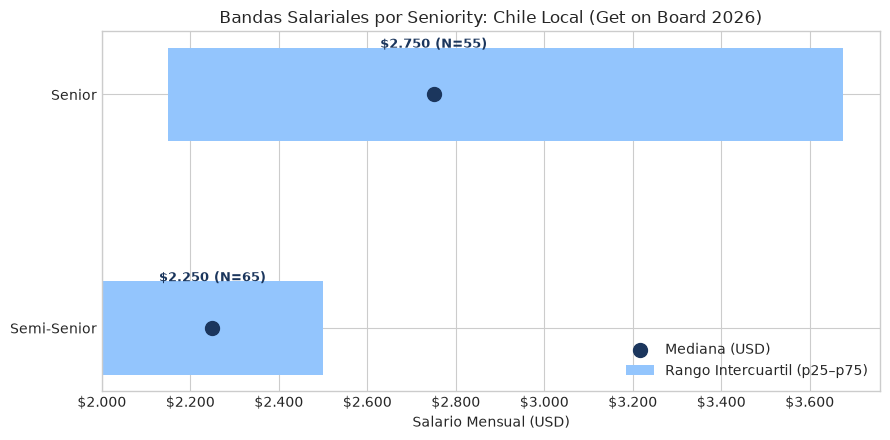

In [5]:
gob_sal = gob_vac[gob_vac['salario_valido_flag'] == True].copy()

def resumen_bandas(df):
    return df.groupby('seniority_nivel')['salario_mensual_usd'].agg(
        n='count',
        p25=lambda s: s.quantile(0.25),
        mediana='median',
        p75=lambda s: s.quantile(0.75)
    ).reset_index()

bandas_cl = resumen_bandas(gob_sal[gob_sal['alcance_geo'] == 'Chile Local'])
bandas_rem = resumen_bandas(gob_sal[gob_sal['alcance_geo'] == 'Remoto sin país declarado'])

fig, ax = plt.subplots(figsize=(9, 4.5))
niveles = ['Semi-Senior', 'Senior']
cl_plot = bandas_cl.set_index('seniority_nivel').reindex(niveles).reset_index()

y = np.arange(len(cl_plot))
ax.barh(y, cl_plot['p75'] - cl_plot['p25'], left=cl_plot['p25'], height=0.4, color='#93C5FD', label='Rango Intercuartil (p25–p75)')
ax.scatter(cl_plot['mediana'], y, color='#1B365D', s=100, zorder=5, label='Mediana (USD)')

for idx, row in cl_plot.iterrows():
    y_pos = y[idx]
    ax.text(row['mediana'], y_pos + 0.2, f"${row['mediana']:,.0f} (N={int(row['n'])})".replace(',', '.'),
            ha='center', fontweight='bold', color='#1B365D', fontsize=9)

ax.set_yticks(y)
ax.set_yticklabels(cl_plot['seniority_nivel'])
ax.set_xlabel('Salario Mensual (USD)')
ax.set_title('Bandas Salariales por Seniority: Chile Local (Get on Board 2026)')
ax.legend(loc='lower right')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}".replace(',', '.')))
plt.show()

## 4. Pregunta de Investigación 3 (P3): Modalidad, Alcance y Comparación INE
**Pregunta de Negocio (P3):** *¿Existe una prima salarial estadísticamente atribuible al trabajo remoto frente al presencial en Chile?*

**Hallazgo Clave (PASO 4.3):** La composición por seniority explica parte de la diferencia, no toda: entre cargos Senior, las ofertas remotas sin país declarado tienen mediana $3.750 frente a $3.750 en Chile Local (diferencia concluyente: +$2.000$701 USD, IC 95% bootstrap [$500, $1.550]); entre Semi-Senior la remota es menor ($2.000 vs $2.250, diferencia no concluyente: -$701 USD, IC 95% [$-575, $625]). Modalidad y alcance no se pueden separar con estos datos, y no se sabe si las ofertas remotas admiten residentes en Chile. Frente a la mediana nacional del INE ESI 2025 ($2.000 CLP / $701 USD), los cargos en Chile Local ($2.250$701 USD mediana) representan 3,21x la mediana del INE (220,9%).

=== COMPOSICIÓN MODALIDAD X SENIORITY (GOB) ===


seniority_nivel,Junior,Lead,Semi-Senior,Senior,Trainee
modalidad_grupo,,,,,
Híbrido,10,3,48,42,0
Presencial,3,0,17,13,1
Remoto Local,1,1,13,30,0
Remoto Total,3,3,19,28,0


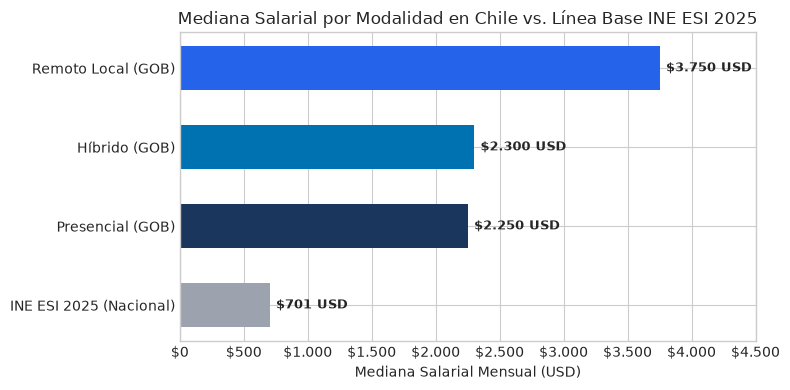

In [6]:
comp_q12 = gob_sal.groupby(['modalidad_grupo', 'seniority_nivel']).size().unstack(fill_value=0)
print("=== COMPOSICIÓN MODALIDAD X SENIORITY (GOB) ===")
display(comp_q12)

med_cl_local = gob_sal[gob_sal['modalidad_grupo'] == 'Presencial']['salario_mensual_usd'].median()
med_hibrido  = gob_sal[gob_sal['modalidad_grupo'] == 'Híbrido']['salario_mensual_usd'].median()
med_rem_loc  = gob_sal[gob_sal['modalidad_grupo'] == 'Remoto Local']['salario_mensual_usd'].median()
med_ine_usd = 701.18

fig, ax = plt.subplots(figsize=(8, 4))
bar_data = pd.Series({
    'INE ESI 2025 (Nacional)': med_ine_usd,
    'Presencial (GOB)': med_cl_local,
    'Híbrido (GOB)': med_hibrido,
    'Remoto Local (GOB)': med_rem_loc
})

bars = ax.barh(bar_data.index, bar_data.values, color=['#9CA3AF', '#1B365D', '#0072B2', '#2563EB'], height=0.55)
for b in bars:
    w = b.get_width()
    ax.text(w + 50, b.get_y() + b.get_height()/2, f"${w:,.0f} USD".replace(',', '.'), va='center', fontweight='bold', fontsize=9)

ax.set_xlim(0, 4500)
ax.set_xlabel('Mediana Salarial Mensual (USD)')
ax.set_title('Mediana Salarial por Modalidad en Chile vs. Línea Base INE ESI 2025')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}".replace(',', '.')))
plt.show()

## 5. Pregunta de Investigación 4 (P4): Posicionamiento Regional y Serie Temporal
**Pregunta de Negocio (P4):** *¿Cómo se posiciona Chile en remuneraciones respecto al resto de Latinoamérica bajo suficiencia muestral N >= 30 y qué tendencias refleja la serie temporal internacional?*

**Hallazgo Clave (PASO 4.4):** En Latinoamérica (Stack Overflow 2024, N ≥ 30), Uruguay registra la mediana más alta ($6.416 USD, 36). Chile ($3.064 USD, 46) se sitúa en un grupo estadísticamente no diferenciable frente a Argentina ($2.958 USD, 124), México ($2.633 USD, 164) y Colombia ($2.500 USD, 83) (todos los intervalos de confianza bootstrap del 95% de las diferencias con Chile incluyen el 0). Brasil registra $2.020 USD (673) y Venezuela $1.000 USD (33). En Data Science Salaries (residentes en EE.UU.), la mediana pasó de $9.917 USD en 2020 (28 < 30) a $12.500 USD en 2023 (3854) y $11.673 USD en 2024 (506).

Cargando matriz TLC desde: 03_Fase_Procesar_Process/datos_limpios_processed/Matriz_TLC_19_Paises_LatAm.csv


,pais,n_sal,cumple_n30,med_usd,ic95_mediana_inf_usd,ic95_mediana_sup_usd
0,Brasil,673,True,2020.25,1864.83,2148.08
1,México,164,True,2632.54,2282.12,2696.80
2,Argentina,124,True,2958.34,2309.42,3939.88
3,Colombia,83,True,2500.00,1471.92,3616.75
4,Chile,46,True,3063.55,2382.95,3700.75
5,Uruguay,36,True,6416.41,5625.00,7710.42
6,Perú,29,False,2200.50,NaN,NaN
7,Venezuela,33,True,1000.00,666.67,1666.67
8,Ecuador,25,False,1500.00,NaN,NaN
9,Costa Rica,20,False,6096.04,NaN,NaN


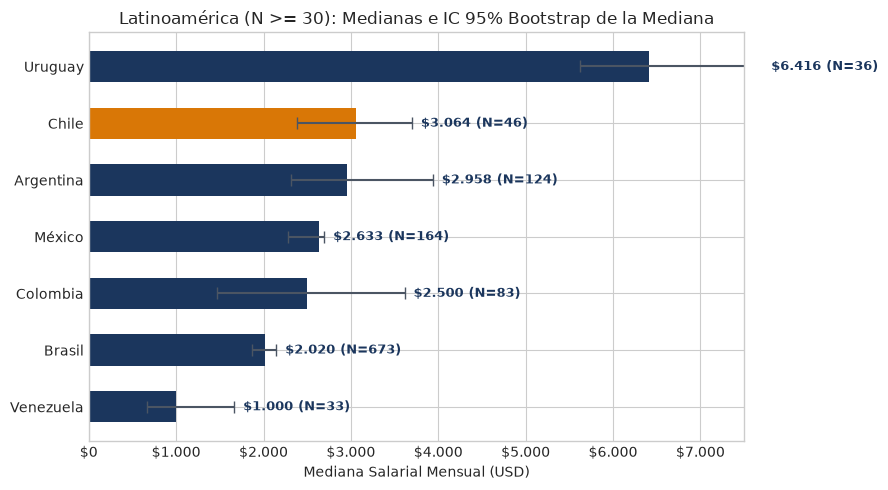

In [7]:
candidate_tlc = [
    DATA_DIR / "Matriz_TLC_19_Paises_LatAm.csv",
    Path("descargas/Matriz_TLC_19_Paises_LatAm.csv"),
    Path("../descargas/Matriz_TLC_19_Paises_LatAm.csv")
]
tlc_file = next((f for f in candidate_tlc if f.exists()), None)

if tlc_file:
    df_tlc = pd.read_csv(tlc_file)
    print(f"Cargando matriz TLC desde: {tlc_file}")
    display(df_tlc[['pais', 'n_sal', 'cumple_n30', 'med_usd', 'ic95_mediana_inf_usd', 'ic95_mediana_sup_usd']].head(10))
else:
    raise FileNotFoundError("Archivo Matriz_TLC_19_Paises_LatAm.csv no encontrado")

df_p4_plot = df_tlc[df_tlc['cumple_n30'] == True].sort_values('med_usd', ascending=True).reset_index(drop=True)

fig, ax = plt.subplots(figsize=(9, 5))
y_pos = np.arange(len(df_p4_plot))
xerr_inf = df_p4_plot['med_usd'] - df_p4_plot['ic95_mediana_inf_usd']
xerr_sup = df_p4_plot['ic95_mediana_sup_usd'] - df_p4_plot['med_usd']

colors_latam = ['#D97706' if p == 'Chile' else '#1B365D' for p in df_p4_plot['pais']]
ax.barh(y_pos, df_p4_plot['med_usd'], xerr=[xerr_inf, xerr_sup], capsize=4, color=colors_latam, height=0.55, 
        error_kw={'elinewidth': 1.5, 'ecolor': '#4B5563'})

for idx, row in df_p4_plot.iterrows():
    ax.text(row['ic95_mediana_sup_usd'] + 100, idx, f"${row['med_usd']:,.0f} (N={int(row['n_sal'])})".replace(',', '.'),
            va='center', fontsize=9, fontweight='bold', color='#1B365D')

ax.set_yticks(y_pos)
ax.set_yticklabels(df_p4_plot['pais'])
ax.set_xlabel('Mediana Salarial Mensual (USD)')
ax.set_title('Latinoamérica (N >= 30): Medianas e IC 95% Bootstrap de la Mediana')
ax.xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, _: f"${x:,.0f}".replace(',', '.')))
ax.set_xlim(0, 7500)
plt.show()

## 6. Profundización Q11: Matriz Volumen vs. Compensación y Efecto Cloud
**Análisis:** Al cruzar el volumen de demanda con la remuneración observada en Get on Board dentro del nivel Senior, se evalúa si el conocimiento de Cloud confiere una prima concluyente.

**Hallazgo Clave (PASO 4.5):** Al comparar ofertas remotas sin país declarado frente a ofertas en Chile Local dentro del nivel Senior en Get on Board, la diferencia observada es de +$1.000 USD ($3.750 vs $2.750 USD, IC 95% bootstrap [$500, $1.550], concluyente). Entre Semi-Senior, la diferencia es de $-250 USD ($2.000 vs $2.250 USD, IC 95% [$-575, $625], no concluyente). En vacantes con tecnologías Cloud frente a vacantes sin Cloud en Senior ($3.750 vs $3.000 USD, diferencia observada de +$750 USD), los intervalos de confianza del 95% incluyen el 0, por lo que la diferencia no resulta estadísticamente concluyente al controlar por seniority.

In [8]:
candidate_ic = [
    Path("04_Fase_Analizar_Analyze/resumenes/resumen_ic_diferencias.csv"),
    Path("../04_Fase_Analizar_Analyze/resumenes/resumen_ic_diferencias.csv"),
    DATA_DIR / "resumen_ic_diferencias.csv"
]
ic_file = next((f for f in candidate_ic if f.exists()), None)

if ic_file:
    df_ic = pd.read_csv(ic_file)
    print("=== INTERVALOS DE CONFIANZA BOOTSTRAP DEL 95% PARA DIFERENCIAS DE MEDIANAS ===")
    display(df_ic[['comparacion', 'diferencia_observada_usd', 'ic95_inf_usd', 'ic95_sup_usd', 'concluyente']])
else:
    raise FileNotFoundError("Archivo resumen_ic_diferencias.csv no encontrado")

=== INTERVALOS DE CONFIANZA BOOTSTRAP DEL 95% PARA DIFERENCIAS DE MEDIANAS ===


,comparacion,diferencia_observada_usd,ic95_inf_usd,ic95_sup_usd,concluyente
0,Chile − Argentina (SO LatAm),105.21,-1121.88,1114.25,False
1,Chile − México (SO LatAm),431.01,-267.34,1183.83,False
2,Chile − Colombia (SO LatAm),563.55,-802.21,1840.67,False
3,Senior Remoto sin país − Senior Chile Local (GOB),1000.00,500.00,1550.00,True
4,Semi-Senior Remoto sin país − Semi-Senior Chil...,-250.00,-575.00,625.00,False
5,AWS − SQL (Senior GOB),750.00,-300.00,1350.00,False
6,Microsoft Azure − SQL (Senior GOB),750.00,-150.00,1400.00,False
7,Google Cloud − SQL (Senior GOB),750.00,-650.00,1400.00,False


## 7. Plan de Acción y Tabla de Recomendaciones Estratégicas (PASO 4.6)
A partir de los hallazgos estadísticamente fundamentados, se adopta una matriz de implementación Qué / Quién / Cuándo / KPI unificada para todo el portafolio:

| # | Qué hay que hacer (Acción concreta) | Quién debería hacerlo | Cuándo (Plazo) | Indicador Clave de Rendimiento (KPI) |
|---|---|---|---|---|
| **1** | Alinear currículo formativo a las 3 tecnologías líderes (SQL, AWS, Python) con electivos en cloud computing. | Academia de formación digital | Trimestre 1 (Q1) | Porcentaje de cobertura de tecnologías top en sílabos (meta: ≥ 80% sobre las 3 tecnologías ≥ 20%). |
| **2** | Calibrar bandas salariales diferenciando explícitamente entre vacantes de Chile Local y Remoto sin país declarado. | Consultora de RRHH tech | Trimestre 1 (Q1) | Tasa de ofertas con salario publicado clasificadas por alcance local vs remoto (meta: 100%). |
| **3** | Diseñar rutas de transición y nivelación técnica de Semi-Senior a Senior con foco en diseño de sistemas y arquitectura cloud. | Academia y Consultora en conjunto | Trimestre 2 (Q2) | Brecha porcentual observada entre tramos Semi-Senior y Senior (22,2% en Chile Local). |

---
*Fin del cuaderno analítico reproducible.*